# 05. A small variational quantum classifier (PennyLane)
Classifies Iris **setosa vs versicolor** using the first two features (sepal length and width), encoded as rotation angles on 2 qubits.

Circuit: `RY(x₀) RY(x₁)` → `RY(θ₀) RY(θ₁)` → `CNOT(0,1)` → `RY(θ₂) RY(θ₃)`, then measure ⟨Z⟩ on **qubit 1**.

**Note.** An earlier version of this notebook measured ⟨Z⟩ on qubit 0 straight after the CNOT. That measurement commutes with a CNOT whose control is qubit 0, so qubit 1 and its feature had no effect. The model was effectively using one feature only. Measuring qubit 1 fixes that, because the CNOT carries information from qubit 0 into it.

In [1]:
import pennylane as qml
from pennylane import numpy as pnp
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

iris = load_iris()
X = iris.data[:100, :2]; y = iris.target[:100]           # setosa (0) vs versicolor (1)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)

lo, hi = Xtr.min(axis=0), Xtr.max(axis=0)                # scale using training data only
scale = lambda A: (A - lo) / (hi - lo) * np.pi
Xtr, Xte = scale(Xtr), scale(Xte)
print(len(Xtr), "train samples,", len(Xte), "test samples")

75 train samples, 25 test samples


In [2]:
n_qubits = 2
dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev)
def circuit(params, x):
    for i in range(n_qubits): qml.RY(x[i], wires=i)          # feature map
    for i in range(n_qubits): qml.RY(params[i], wires=i)     # trainable layer 1
    qml.CNOT(wires=[0, 1])
    for i in range(n_qubits): qml.RY(params[2+i], wires=i)   # trainable layer 2
    return qml.expval(qml.PauliZ(1))

def predict(params, X):
    return pnp.stack([circuit(params, x) for x in X])

def cost(params, X, y):
    return pnp.mean((predict(params, X) - (2*y - 1))**2)     # labels mapped to -1 / +1

def accuracy(params, X, y):
    return float(np.mean((predict(params, X) > 0).astype(int) == y))

In [3]:
pnp.random.seed(0)
params = pnp.array(np.random.uniform(0, np.pi, 4), requires_grad=True)
opt = qml.AdamOptimizer(stepsize=0.1)
ytr_t = pnp.array(ytr, requires_grad=False)
losses = []
for step in range(60):
    params, loss = opt.step_and_cost(lambda p: cost(p, Xtr, ytr_t), params)
    losses.append(float(loss))
print("final training loss:", round(losses[-1], 4))
print("train accuracy:", accuracy(params, Xtr, ytr))
print("test accuracy :", accuracy(params, Xte, yte))

final training loss: 0.2443
train accuracy: 0.9866666666666667
test accuracy : 1.0


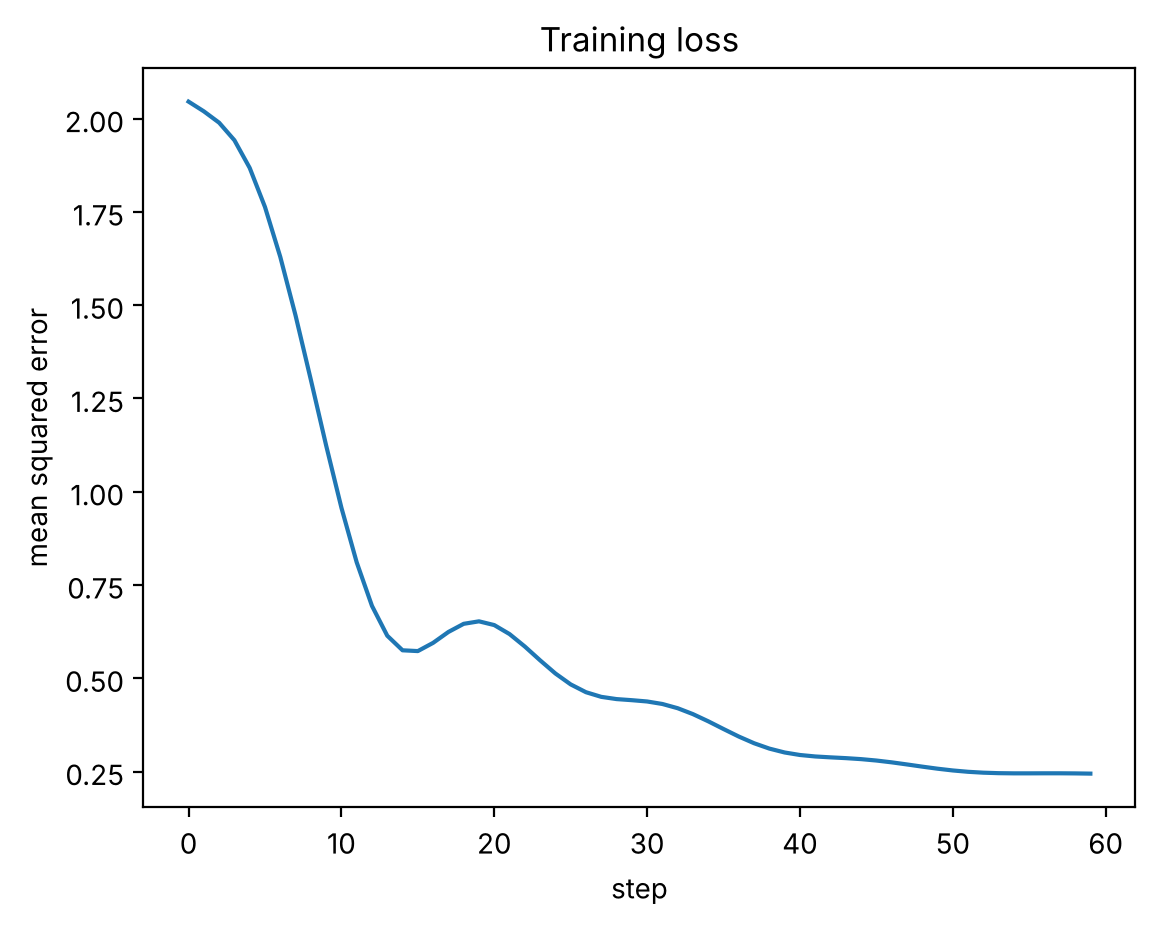

In [4]:
import matplotlib.pyplot as plt
plt.plot(losses); plt.xlabel("step"); plt.ylabel("mean squared error"); plt.title("Training loss"); plt.show()

## Predicting a new sample
A sample is scaled with the same training statistics before being passed to the circuit.

In [5]:
new = scale(np.array([[5.0, 3.4]]))[0]       # sepal length 5.0 cm, width 3.4 cm
p = circuit(params, new)
print("output:", round(float(p), 3), "->", "versicolor" if p > 0 else "setosa")

output: -0.544 -> setosa
